In [5]:
import sys
print(sys.executable)

d:\mini_projects\mini_project2\.venv\Scripts\python.exe


# Cats vs Dogs CNN Classifier
## 1. Dataset Exploration

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
from pathlib import Path

print(Path.cwd())

d:\mini_projects\mini_project2\notebooks


In [8]:
test_path = Path("../data/dogs_vs_cats_subset/test")

print("Path exists:", test_path.exists())
print("Is directory:", test_path.is_dir())

Path exists: True
Is directory: True


In [9]:
test_path = Path("../data/dogs_vs_cats_subset/test")
test_set_img = list(sorted(test_path.glob("*.jpg")))


for img in test_set_img[:5]:
    print(img.name)


1.jpg
10.jpg
100.jpg
11.jpg
12.jpg


In [10]:
print("Number of images in test set:", len(test_set_img) )

Number of images in test set: 100


Image shape: (499, 381, 3)


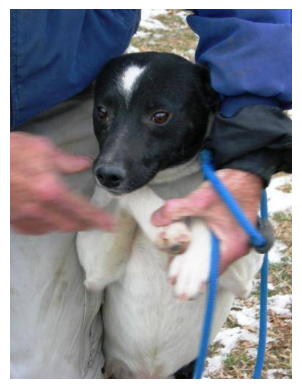

Image shape: (374, 500, 3)


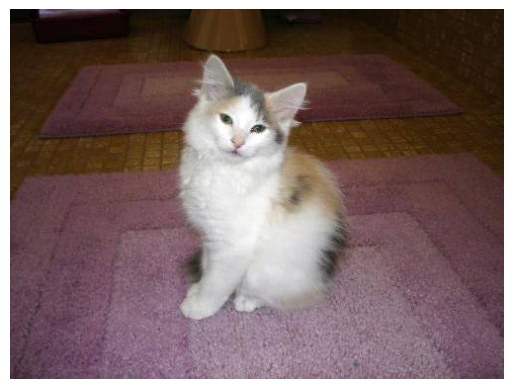

Image shape: (343, 499, 3)


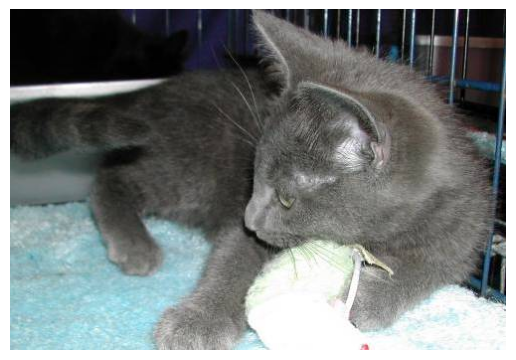

Image shape: (370, 278, 3)


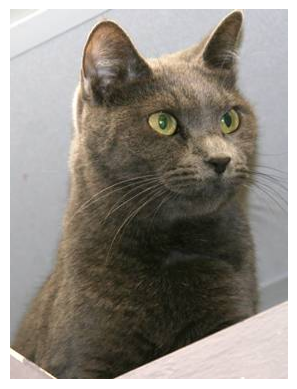

Image shape: (465, 315, 3)


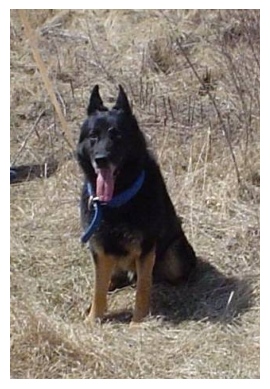

In [11]:
import cv2
from PIL import Image
for img in test_set_img[:5]:
    image = cv2.imread(str(img))
    print(f"Image shape: {image.shape}")
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

In [12]:
train_path = Path("../data/dogs_vs_cats_subset/train")
train_set_img = list(sorted(train_path.glob("*.jpg")))

print("Number of images in training set:", len(train_set_img))
print("Number of images in test set:", len(test_set_img))

for img in train_set_img[:5]:
    print(img.name)

Number of images in training set: 1000
Number of images in test set: 100
cat.0.jpg
cat.1.jpg
cat.10.jpg
cat.100.jpg
cat.101.jpg


In [13]:
val_path = Path("../data/dogs_vs_cats_subset/val")
val_set_img = list(sorted(val_path.glob("*.jpg")))

print("Number of images in validation set:", len(val_set_img))

Number of images in validation set: 200


In [14]:
dog_img=0
cat_img=0
for img in train_set_img:
    if "dog" in img.name:
        dog_img+=1
    elif "cat" in img.name:
        cat_img+=1
print(f"Number of dog images in training set: {dog_img}")
print(f"Number of cat images in training set: {cat_img}")

Number of dog images in training set: 500
Number of cat images in training set: 500


In [15]:
min_ht= float('inf')
min_wd= float('inf')
max_ht= 0
max_wd= 0
unreadable=0
grayscale_count=0
for img in test_set_img:
    image = cv2.imread(str(img))
    if(image is None):
        unreadable+=1
        print(f"Unreadable image: {img.name}")
        continue
    min_ht = min(min_ht, image.shape[0])
    min_wd = min(min_wd, image.shape[1])
    max_ht = max(max_ht, image.shape[0])
    max_wd = max(max_wd, image.shape[1])
    ima = Image.open(img)
    if ima.mode == 'L':
        grayscale_count += 1

print(f"Minimum height: {min_ht}")
print(f"Minimum width: {min_wd}")
print(f"Maximum height: {max_ht}")
print(f"Maximum width: {max_wd}")
print(f"Number of grayscale images: {grayscale_count}")
print(f"Number of unreadable images: {unreadable}")

Minimum height: 50
Minimum width: 41
Maximum height: 500
Maximum width: 500
Number of grayscale images: 0
Number of unreadable images: 0


In [16]:
min_ht= float('inf')
min_wd= float('inf')
max_ht= 0
max_wd= 0
unreadable=0
grayscale_count=0
for img in train_set_img:
    image = cv2.imread(str(img))
    if(image is None):
        unreadable+=1
        print(f"Unreadable image: {img.name}")
        continue
    min_ht = min(min_ht, image.shape[0])
    min_wd = min(min_wd, image.shape[1])
    max_ht = max(max_ht, image.shape[0])
    max_wd = max(max_wd, image.shape[1])
    ima = Image.open(img)
    if ima.mode == 'L':
        grayscale_count += 1
    
print(f"Minimum height: {min_ht}")
print(f"Minimum width: {min_wd}")
print(f"Maximum height: {max_ht}")
print(f"Maximum width: {max_wd}")
print(f"Number of unreadable images: {unreadable}")
print(f"Number of grayscale images: {grayscale_count}")

Minimum height: 81
Minimum width: 80
Maximum height: 500
Maximum width: 500
Number of unreadable images: 0
Number of grayscale images: 0


In [17]:
min_ht= float('inf')
min_wd= float('inf')
max_ht= 0
max_wd= 0
unreadable=0
grayscale_count=0
for img in val_set_img:
    image = cv2.imread(str(img))
    if(image is None):
        unreadable+=1
        print(f"Unreadable image: {img.name}")
        continue
    min_ht = min(min_ht, image.shape[0])
    min_wd = min(min_wd, image.shape[1])
    max_ht = max(max_ht, image.shape[0])
    max_wd = max(max_wd, image.shape[1])
    ima = Image.open(img)
    if ima.mode == 'L':
        grayscale_count += 1
print(f"Minimum height: {min_ht}")
print(f"Minimum width: {min_wd}")
print(f"Maximum height: {max_ht}")
print(f"Maximum width: {max_wd}")
print(f"Number of unreadable images: {unreadable}")
print(f"Number of grayscale images: {grayscale_count}")

Minimum height: 120
Minimum width: 156
Maximum height: 500
Maximum width: 500
Number of unreadable images: 0
Number of grayscale images: 0


In [45]:

import tensorflow as tf


In [18]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "dogs_vs_cats_subset"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print("Training directory exists:", TRAIN_DIR.exists())
print("Validation directory exists:", VAL_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())

Training directory exists: True
Validation directory exists: True
Test directory exists: True


In [19]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

In [20]:
train_paths = sorted(TRAIN_DIR.glob("*.jpg"))
val_paths = sorted(VAL_DIR.glob("*.jpg"))

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 1000
Validation images: 200


In [21]:
class_names = ["cat", "dog"]

train_labels = [
    0 if path.name.startswith("cat.") else 1
    for path in train_paths
]

val_labels = [
    0 if path.name.startswith("cat.") else 1
    for path in val_paths
]

print("Class mapping:", {name: i for i, name in enumerate(class_names)})
print("First 5 filenames:", [p.name for p in train_paths[:5]])
print("First 5 labels:", train_labels[:5])

Class mapping: {'cat': 0, 'dog': 1}
First 5 filenames: ['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg', 'cat.100.jpg', 'cat.101.jpg']
First 5 labels: [0, 0, 0, 0, 0]


In [22]:
train_ds = tf.data.Dataset.from_tensor_slices(
    ( [str(p) for p in train_paths], train_labels )
)

val_ds = tf.data.Dataset.from_tensor_slices(
    ( [str(p) for p in val_paths], val_labels )
)

In [23]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

In [24]:
train_ds = train_ds.map(load_image)
val_ds = val_ds.map(load_image)

In [25]:
train_ds = train_ds.shuffle(1000, seed=42).batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)

In [26]:
for images, labels in train_ds.take(1):
    print("Images:", images.shape, images.dtype)
    print("Labels:", labels.shape, labels.dtype)
    print("Pixel range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())
    print("Labels in batch:", labels[:10].numpy())

Images: (32, 128, 128, 3) <dtype: 'float32'>
Labels: (32,) <dtype: 'int32'>
Pixel range: 0.0 255.0
Labels in batch: [0 1 1 0 0 1 1 0 1 0]


In [27]:
def normalize_image(image, label):
    image = image / 255.0
    return image, label

In [28]:
train_ds = train_ds.map(normalize_image)
val_ds = val_ds.map(normalize_image)

In [29]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image shape: (32, 128, 128, 3)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [30]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Pixel range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())
    print("Label range:",
          tf.reduce_min(labels).numpy(),
          tf.reduce_max(labels).numpy())

Image shape: (32, 128, 128, 3)
Pixel range: 0.0 1.0
Label range: 0 1


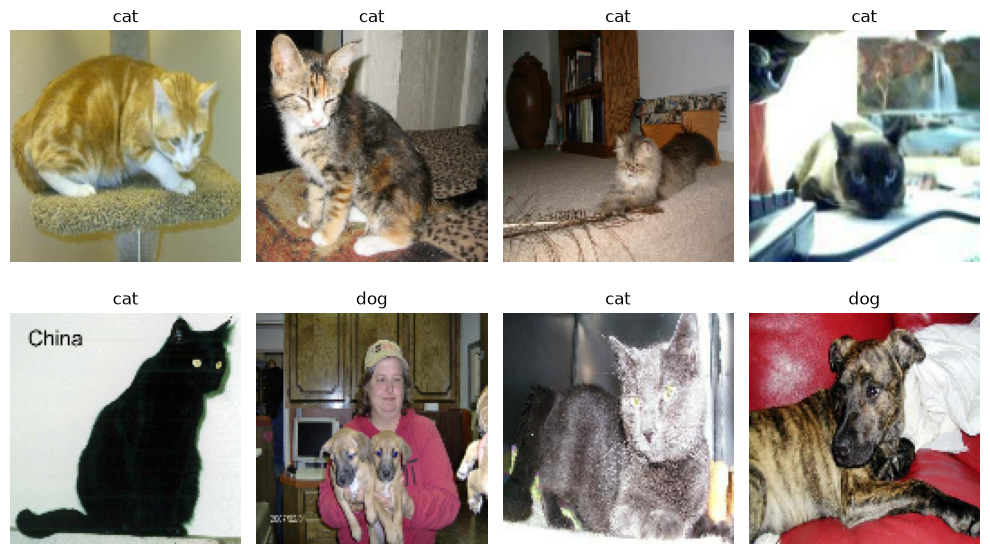

In [31]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 6))

    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [32]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [33]:
test_paths = sorted(TEST_DIR.glob("*.jpg"))

print("Number of test images:", len(test_paths))
print("First 5 filenames:", [p.name for p in test_paths[:5]])

Number of test images: 100
First 5 filenames: ['1.jpg', '10.jpg', '100.jpg', '11.jpg', '12.jpg']


In [34]:
test_ds = tf.data.Dataset.from_tensor_slices(
    [str(p) for p in test_paths]
)

In [35]:
def load_test_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image

In [36]:
test_ds = test_ds.map(load_test_image)
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [37]:
for images in test_ds.take(1):
    print("Test batch shape:", images.shape)
    print("Pixel range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())

Test batch shape: (32, 128, 128, 3)
Pixel range: 0.0 1.0


In [38]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [39]:
IMG_SIZE = (128, 128)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [40]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [42]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


d:\mini_projects\mini_project2\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - accuracy: 0.5040 - loss: 0.7181 - val_accuracy: 0.5350 - val_loss: 0.6927
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.5500 - loss: 0.6916 - val_accuracy: 0.5000 - val_loss: 0.6914
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.5150 - loss: 0.6954 - val_accuracy: 0.6100 - val_loss: 0.6873
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.5920 - loss: 0.6780 - val_accuracy: 0.5350 - val_loss: 0.6699
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.6410 - loss: 0.6355 - val_accuracy: 0.6350 - val_loss: 0.6394
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.6760 - loss: 0.5979 - val_accuracy: 0.6000 - val_loss: 0.6374
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.7260 - loss: 0.5394 - val_accuracy: 0.6650 - val_loss: 0.6198
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 0.7640 - loss: 0.4751 - val_accuracy: 0.6700 - val_l

In [43]:
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model.save(MODEL_DIR / "baseline_cnn.keras")

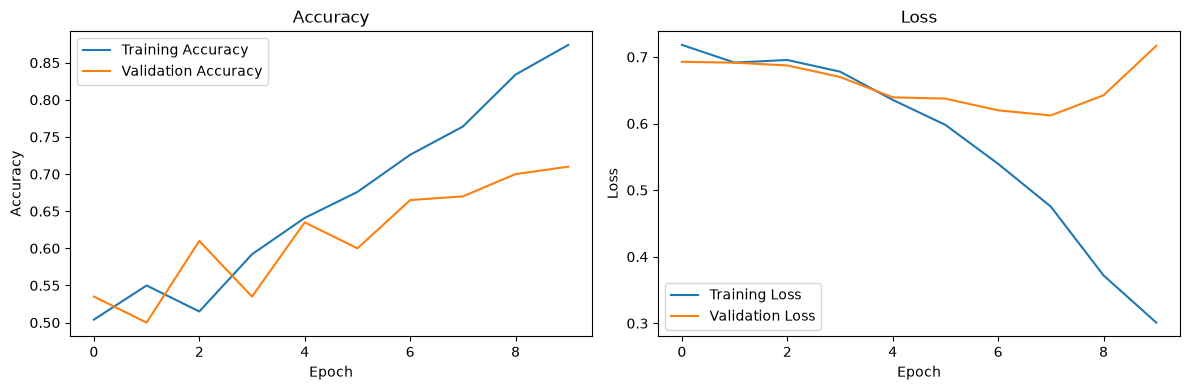

In [44]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.show()

In [45]:
#model evaluation

In [2]:
import tensorflow as tf
from pathlib import Path

MODEL_PATH = Path("../models/baseline_cnn.keras")
model = tf.keras.models.load_model(MODEL_PATH)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,914,309 (37.82 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,609,540 (25.21 MB)

In [46]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7100 - loss: 0.7167
Validation loss: 0.7167
Validation accuracy: 0.7100


In [47]:
import numpy as np

y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

y_prob = model.predict(val_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


              precision    recall  f1-score   support

         Cat       0.70      0.74      0.72       100
         Dog       0.72      0.68      0.70       100

    accuracy                           0.71       200
   macro avg       0.71      0.71      0.71       200
weighted avg       0.71      0.71      0.71       200



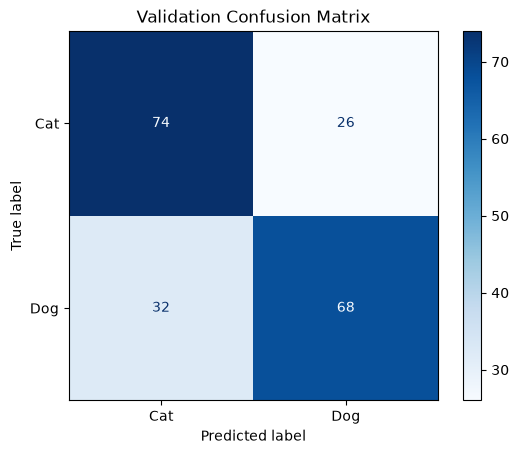

In [48]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cat", "Dog"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
).plot(cmap="Blues")

plt.title("Validation Confusion Matrix")
plt.show()

In [49]:
misclassified = np.where(y_true != y_pred)[0]

print("Misclassified images:", len(misclassified))
print("Total validation images:", len(y_true))

Misclassified images: 58
Total validation images: 200
